In [3]:
from astropy.table import Table
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import ligo.skymap.plot
from astropy import units as u
from astropy.coordinates import SkyCoord
import lal
lal.swig_redirect_standard_output_error(False)

/home/ir-band1/1-research/miniconda/envs/clustering-3.12/lib/python3.12/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


True

In [6]:

legacy_path = "/home/ir-band1/1-research/1-4MOST/3-CRS/2-data/1-BG/desi_bg_nomaskbit_mask_4M_reduced_columns.fits"


In [7]:
cat = Table.read(legacy_path)

In [8]:
# Plot RAmax vs Decmax using a density hexbin (efficient for large datasets)
ra= cat['RA']
dec = cat['DEC']

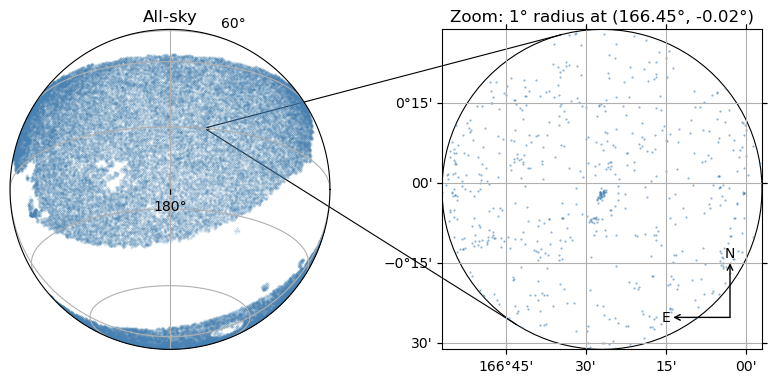

In [9]:
# Fix plotting by using the correct world transform and a true 1°-radius selection

# Define zoom center and radius
ra0, dec0 = 166.45, -0.02
radius_deg = 0.5

# Fast preselection in a small box, then precise great-circle cut
dra = np.abs((ra - ra0 + 180) % 360 - 180)  # wrap-aware RA difference
pre = (dra <= radius_deg * 1.2) & (np.abs(dec - dec0) <= radius_deg * 1.2)

sel_zoom = np.zeros(len(ra), dtype=bool)
if np.any(pre):
    ra_r = np.deg2rad(ra[pre])
    dec_r = np.deg2rad(dec[pre])
    ra0_r = np.deg2rad(ra0)
    dec0_r = np.deg2rad(dec0)
    cosd = np.sin(dec_r) * np.sin(dec0_r) + np.cos(dec_r) * np.cos(dec0_r) * np.cos(ra_r - ra0_r)
    sep = np.rad2deg(np.arccos(np.clip(cosd, -1.0, 1.0)))
    idx_pre = np.where(pre)[0]
    sel_zoom[idx_pre] = sep <= radius_deg

# All-sky + 1° zoom inset around (RA, Dec) = (166.45°, -0.02°)
fig = plt.figure(figsize=(9, 4), dpi=100)

ax_globe = plt.axes(
    [0.05, 0.1, 0.5, 0.8],
    projection='astro degrees globe',
    center='180d -23d')

ax_zoom_circle = plt.axes(
    [0.58, 0.1, 0.4, 0.8],
    projection='astro degrees zoom',
    center=f'{ra0}d {dec0}d',
    radius=f'{radius_deg} deg')

ax_globe.mark_inset_circle(ax_zoom_circle, f'{ra0}d {dec0}d', f'{radius_deg} deg')
ax_globe.connect_inset_circle(ax_zoom_circle, f'{ra0}d {dec0}d', f'{radius_deg} deg')

# Downsample for the globe for speed
n_globe = min(200_000, len(ra))
if n_globe < len(ra):
    rng = np.random.default_rng(42)
    sel_globe = rng.choice(len(ra), size=n_globe, replace=False)
    ax_globe.scatter(
        ra[sel_globe], dec[sel_globe], s=0.05, color='steelblue', alpha=0.3, rasterized=True,
        transform=ax_globe.get_transform('world'))
else:
    ax_globe.scatter(
        ra, dec, s=0.05, color='steelblue', alpha=0.3, rasterized=True,
        transform=ax_globe.get_transform('world'))

# Full density in the zoomed region (true 1° circle)
ax_zoom_circle.scatter(
    ra[sel_zoom], dec[sel_zoom], s=0.3, color='steelblue', alpha=0.6, rasterized=True,
    transform=ax_zoom_circle.get_transform('world'))

for ax in [ax_globe, ax_zoom_circle]:
    ax.grid()
    ax.set_facecolor('none')
    for key in ['ra', 'dec']:
        ax.coords[key].set_auto_axislabel(False)

# ax_zoom_circle.scalebar((0.1, 0.1), 5 * u.deg).label()
ax_zoom_circle.compass(0.9, 0.1, 0.2)

ax_globe.set_title('All-sky')
ax_zoom_circle.set_title('Zoom: 1° radius at (166.45°, -0.02°)')
plt.show()

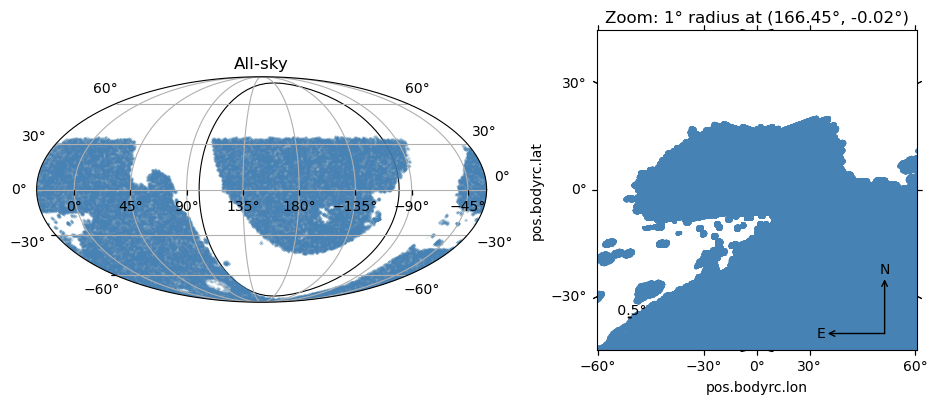

In [37]:
# Fix plotting by using the correct world transform and a true 1°-radius selection

# Define zoom center and radius
ra0, dec0 = 0, 0
radius_deg =100

# Fast preselection in a small box, then precise great-circle cut
dra = np.abs((ra - ra0 + 180) % 360 - 180)  # wrap-aware RA difference
pre = (dra <= radius_deg * 1.2) & (np.abs(dec - dec0) <= radius_deg * 1.2)

sel_zoom = np.zeros(len(ra), dtype=bool)
if np.any(pre):
    ra_r = np.deg2rad(ra[pre])
    dec_r = np.deg2rad(dec[pre])
    ra0_r = np.deg2rad(ra0)
    dec0_r = np.deg2rad(dec0)
    cosd = np.sin(dec_r) * np.sin(dec0_r) + np.cos(dec_r) * np.cos(dec0_r) * np.cos(ra_r - ra0_r)
    sep = np.rad2deg(np.arccos(np.clip(cosd, -1.0, 1.0)))
    idx_pre = np.where(pre)[0]
    sel_zoom[idx_pre] = sep <= radius_deg

# All-sky + 1° zoom inset around (RA, Dec) = (166.45°, -0.02°)
fig = plt.figure(figsize=(9, 4), dpi=100)

ax_globe = plt.axes(
    [0.05, 0.1, 0.5, 0.8],
    projection='geo mollweide',
    center='150d 0d')

ax_zoom_circle = plt.axes(
    [0.65, 0.1, 0.4, 0.8],
    projection='geo degrees zoom',
    center=f'{ra0}d {dec0}d',
    radius=f'{radius_deg} deg')

ax_globe.mark_inset_circle(ax_zoom_circle, f'{ra0}d {dec0}d', f'{radius_deg} deg')
ax_globe.connect_inset_circle(ax_zoom_circle, f'{ra0}d {dec0}d', f'{radius_deg} deg')

# Downsample for the globe for speed
n_globe = min(200_000, len(ra))
if n_globe < len(ra):
    rng = np.random.default_rng(42)
    sel_globe = rng.choice(len(ra), size=n_globe, replace=False)
    ax_globe.scatter(
        ra[sel_globe], dec[sel_globe], s=0.05, color='steelblue', alpha=0.3, rasterized=True,
        transform=ax_globe.get_transform('world'))
else:
    ax_globe.scatter(
        ra, dec, s=0.05, color='steelblue', alpha=0.3, rasterized=True,
        transform=ax_globe.get_transform('world'))

# Full density in the zoomed region (true 1° circle)
ax_zoom_circle.scatter(
    ra[sel_zoom], dec[sel_zoom], s=0.3, color='steelblue', alpha=0.6, rasterized=True,
    transform=ax_zoom_circle.get_transform('world'))

for ax in [ax_globe]:
    ax.grid()
    ax.set_facecolor('none')
    # for key in ['ra', 'dec']:
    #     ax.coords[key].set_auto_axislabel(False)

ax_zoom_circle.scalebar((0.1, 0.1), 0.5 * u.deg).label()
ax_zoom_circle.compass(0.9, 0.05, 0.2)

ax_globe.set_title('All-sky')
ax_zoom_circle.set_title('Zoom: 1° radius at (166.45°, -0.02°)')
plt.show()

In [39]:
def projection_dec(dec):
        """Shift `dec` to the origin of the Axes object and convert to radians.

        Parameters
        ----------
        dec : array-like
            Declination in degrees.

        Returns
        -------
        array-like
            `dec` converted to plot coordinates.
        """
        return np.radians(dec)

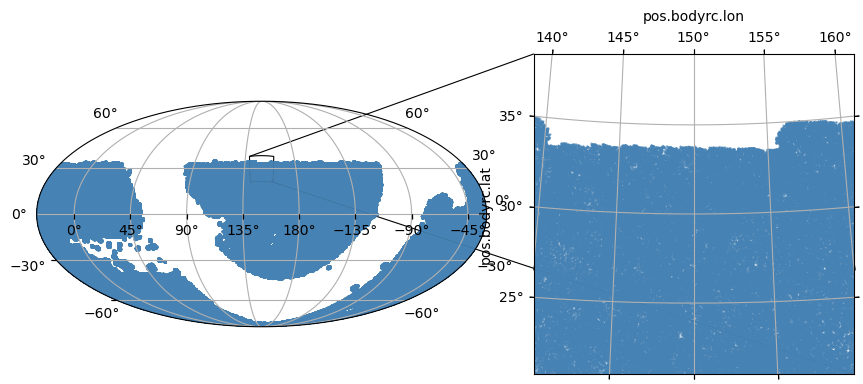

In [ ]:
fig = plt.figure(figsize=(9, 4), dpi=100)

ax_globe = plt.axes(
    [0.05, 0.1, 0.5, 0.8],
    projection='geo degrees mollweide',
    center='115d 0d')

ax_zoom_rect = plt.axes(
    [0.58, 0.1, 0.4, 0.8],
    projection='geo degrees zoom',
    center='115d +30d',
    radius='9 deg')
for reg in ['ngc','sgc']:
    pol = np.load(os.path.join(mask_dir, f'4most_{reg}_newfootprint.npy'), allow_pickle=True).T
    m=pol[1] < np.radians(-20)
    if reg == 'ngc':
        rra = np.linspace(0,360, 100)
        tt = projection_ra(rra, ra_center=115)
        tt = np.remainder(tt + np.pi*2, np.pi*2)
        tt[tt > np.pi] -= np.pi*2
        mm = (tt<pol[0][m].max()) & (tt>pol[0][m].min())
        ttt = tt[mm] - np.radians(115) + np.radians(rot)
        ttt = np.remainder(ttt + np.pi*2, np.pi*2)
        ttt[ttt > np.pi] -= np.pi*2
        ax.plot(ttt, projection_dec([-20]*100)[mm], lw=1, c='tab:red', ls='--', zorder=100)
    pol[0] -= np.radians(115)
    pol[0] += np.radians(rot)
    pol[0] = np.remainder(pol[0] + np.pi*2, np.pi*2)
    pol[0][pol[0] > np.pi] -= np.pi*2
    ax.plot(pol[0], pol[1], color='tab:red', lw=2, zorder=100)
    ax.add_patch(Polygon(pol.T, facecolor='tab:red', alpha=0.2))
    ax.plot(pol[0], pol[1], color='tab:red', lw=2, zorder=100, label='4MOST-CRS')

ax_globe.mark_inset_axes(ax_zoom_rect)
ax_globe.connect_inset_axes(ax_zoom_rect, 'upper left')
ax_globe.connect_inset_axes(ax_zoom_rect, 'lower right')

ax_globe.grid()
ax_zoom_rect.grid()
ax_globe.scatter(
        -ra, dec, s=0.05, color='steelblue', alpha=0.3, rasterized=True,
        transform=ax_globe.get_transform('world'))

# Full density in the zoomed region (true 1° circle)
ax_zoom_rect.scatter(
    ra, dec, s=0.3, color='steelblue', alpha=0.6, rasterized=True,
    transform=ax_zoom_rect.get_transform('world'))

for ax in [ax_globe, ax_zoom_rect]:
    ax.set_facecolor('none')
    # for key in ['ra', 'dec']:
    #     ax.coords[key].set_auto_axislabel(False)